In [ ]:
# Task 4: Machine Learning on RNA-Seq Data

## Dataset

GSE263566 - The Human Cardiac Age-OME

## Objective

To apply machine learning classification algorithms to
RNA-Seq gene expression data to classify human heart
samples into Young and Old groups.

## Workflow

RNA-Seq Expression Data
        ↓
Data Loading
        ↓
Data Inspection
        ↓
Missing Value Checking
        ↓
Sample Group Identification
        ↓
Feature Matrix Preparation
        ↓
Train-Test Split
        ↓
Feature Selection
        ↓
Feature Scaling
        ↓
Machine Learning Classification
        ↓
Model Evaluation
        ↓
PCA Visualization

In [28]:
# Import libraries
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

In [29]:
# Set dataset path
DATA_PATH = "D:/ML/Assignment/GSE263566_ageingRNAcounts.csv.gz"
print("Dataset path:", DATA_PATH)
print("File exists:", os.path.exists(DATA_PATH))

Dataset path: D:/ML/Assignment/GSE263566_ageingRNAcounts.csv.gz
File exists: True


In [30]:
#Load the RNA-Seq dataset
rna = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", rna.shape)

display(rna.head())

Dataset loaded successfully.
Shape: (28395, 17)


,Unnamed: 0,old10,old11,old13,old4,old6,old7,old8,old9,young10,young11,young3,young4,young5,young7,young8,young9
0,100287102,0,2,4,0,5,0,2,3,3,7,2,0,5,1,1,3
1,653635,36,171,378,272,292,277,264,374,220,303,321,264,349,376,190,313
2,102466751,0,0,15,16,13,6,10,12,9,15,12,10,6,23,12,20
3,100302278,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,645520,0,1,0,0,0,0,0,8,0,2,2,0,0,0,0,0


In [31]:
# Inspect column 
print("Number of columns:", len(rna.columns))

print("\nColumn names:")
for column in rna.columns:
    print(column)

Number of columns: 17

Column names:
Unnamed: 0
old10
old11
old13
old4
old6
old7
old8
old9
young10
young11
young3
young4
young5
young7
young8
young9


In [32]:
# dataset information
print("Number of rows:", rna.shape[0])
print("Number of columns:", rna.shape[1])

print("\nFirst 10 columns:")
print(rna.columns[:10].tolist())

Number of rows: 28395
Number of columns: 17

First 10 columns:
['Unnamed: 0', 'old10', 'old11', 'old13', 'old4', 'old6', 'old7', 'old8', 'old9', 'young10']


In [33]:
#Check missing values
total_missing = rna.isnull().sum().sum()

print("Total missing values:", total_missing)
missing_by_column = rna.isnull().sum()

display(
    missing_by_column[missing_by_column > 0]
)

Total missing values: 0


Series([], dtype: int64)

In [34]:
#Check duplicate rows
duplicate_rows = rna.duplicated().sum()

print("Duplicated rows:", duplicate_rows)

Duplicated rows: 0


In [35]:
# Identify gene ID column
gene_column = rna.columns[0]

print("Gene identifier column:", gene_column)

print("\nFirst 10 gene identifiers:")
print(rna[gene_column].head(10).tolist())

Gene identifier column: Unnamed: 0

First 10 gene identifiers:
[100287102, 653635, 102466751, 100302278, 645520, 79501, 729737, 102725121, 102723897, 102465909]


In [36]:
#Set gene IDs as index
rna = rna.set_index(gene_column)

print("Updated dataset shape:", rna.shape)

display(rna.head())

Updated dataset shape: (28395, 16)


,old10,old11,old13,old4,old6,old7,old8,old9,young10,young11,young3,young4,young5,young7,young8,young9
Unnamed: 0,,,,,,,,,,,,,,,,
100287102,0,2,4,0,5,0,2,3,3,7,2,0,5,1,1,3
653635,36,171,378,272,292,277,264,374,220,303,321,264,349,376,190,313
102466751,0,0,15,16,13,6,10,12,9,15,12,10,6,23,12,20
100302278,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
645520,0,1,0,0,0,0,0,8,0,2,2,0,0,0,0,0


In [37]:
#Convert expression values to numeric
rna = rna.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Expression matrix converted to numeric.")
print("Shape:", rna.shape)

Expression matrix converted to numeric.
Shape: (28395, 16)


In [39]:
#Check missing values again
missing_after_conversion = rna.isnull().sum().sum()

print(
    "Missing values after numeric conversion:",
    missing_after_conversion
)

rna = rna.fillna(0)

print(
    "Missing values after replacement:",
    rna.isnull().sum().sum()
)

Missing values after numeric conversion: 0
Missing values after replacement: 0


In [40]:
#Check negative values
negative_values = (rna < 0).sum().sum()

print(
    "Number of negative expression values:",
    negative_values
)

#DO NOT CPM-normalize this dataset
cpm = rna / rna.sum()
np.log2(cpm + 1)

Number of negative expression values: 0


,old10,old11,old13,old4,old6,old7,old8,old9,young10,young11,young3,young4,young5,young7,young8,young9
Unnamed: 0,,,,,,,,,,,,,,,,
100287102,0.000000,9.956825e-08,1.134570e-07,0.000000e+00,2.071147e-07,0.000000e+00,7.266370e-08,9.024149e-08,1.064970e-07,2.380985e-07,6.791889e-08,0.000000e+00,1.736809e-07,4.658564e-08,3.511430e-08,9.774842e-08
653635,0.000004,8.513060e-06,1.072165e-05,9.737070e-06,1.209545e-05,1.001044e-05,9.591577e-06,1.125006e-05,7.809760e-06,1.030623e-05,1.090094e-05,9.721935e-06,1.212288e-05,1.751609e-05,6.671702e-06,1.019838e-05
102466751,0.000000,0.000000e+00,4.254638e-07,5.727706e-07,5.384981e-07,2.168334e-07,3.633185e-07,3.609659e-07,3.194910e-07,5.102111e-07,4.075133e-07,3.682563e-07,2.084171e-07,1.071469e-06,4.213716e-07,6.516560e-07
100302278,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
645520,0.000000,4.978413e-08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.406440e-07,0.000000e+00,6.802815e-08,6.791889e-08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105379557,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
105379559,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
105379561,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [41]:
#Check sample names
sample_names = rna.columns.tolist()

print("Number of samples:", len(sample_names))

print("\nSample names:")

for sample in sample_names:
    print(sample)

Number of samples: 16

Sample names:
old10
old11
old13
old4
old6
old7
old8
old9
young10
young11
young3
young4
young5
young7
young8
young9


In [42]:
#Create sample groups
groups = []

for sample in sample_names:

    sample_lower = sample.lower()

    if sample_lower.startswith("young"):
        groups.append("Young")

    elif sample_lower.startswith("old"):
        groups.append("Old")

    else:
        groups.append("Unknown")

metadata = pd.DataFrame({
    "Sample": sample_names,
    "Group": groups
})

display(metadata)

,Sample,Group
0,old10,Old
1,old11,Old
2,old13,Old
3,old4,Old
4,old6,Old
5,old7,Old
6,old8,Old
7,old9,Old
8,young10,Young
9,young11,Young


In [19]:
#Check groups
print(
    metadata["Group"].value_counts()
)

#Make sure there are no unknown groups
print(
    metadata[metadata["Group"] == "Unknown"]
)


Group
Old      8
Young    8
Name: count, dtype: int64
Empty DataFrame
Columns: [Sample, Group]
Index: []


In [20]:
#Create the ML feature matrix
X = rna.T

print("X shape:")
print(X.shape)

display(X.head())


#Create target variable
y = metadata["Group"]

print("Target:")
print(y)

X shape:
(16, 28395)


Unnamed: 0,100287102,653635,102466751,100302278,645520,79501,729737,102725121,102723897,102465909,...,105379422,105379423,102723382,642249,105379554,105379557,105379559,105379561,102723822,102723891
old10,0,36,0,0,0,0,18,0,31,0,...,0,0,0,0,0,0,0,0,0,0
old11,2,171,0,0,1,0,154,7,181,0,...,0,0,0,0,0,0,0,0,0,0
old13,4,378,15,0,0,0,257,2,303,7,...,0,0,0,0,0,0,0,0,0,0
old4,0,272,16,0,0,0,144,3,246,3,...,0,0,0,0,0,0,0,0,0,0
old6,5,292,13,0,0,0,210,10,339,5,...,0,0,0,0,0,0,0,0,0,0


Target:
0       Old
1       Old
2       Old
3       Old
4       Old
5       Old
6       Old
7       Old
8     Young
9     Young
10    Young
11    Young
12    Young
13    Young
14    Young
15    Young
Name: Group, dtype: object


In [43]:
#Check group distribution
group_counts = metadata["Group"].value_counts()

print("Sample groups:")
display(group_counts)

#Check unknown samples
unknown_samples = metadata[
    metadata["Group"] == "Unknown"
]

display(unknown_samples)

#Prepare X
X = rna.T.copy()

print("Feature matrix shape:", X.shape)

display(X.head())

#Prepare y
y = metadata["Group"].copy()

print("Target variable:")
print(y.tolist())

Sample groups:


Group
Old      8
Young    8
Name: count, dtype: int64

,Sample,Group


Feature matrix shape: (16, 28395)


Unnamed: 0,100287102,653635,102466751,100302278,645520,79501,729737,102725121,102723897,102465909,...,105379422,105379423,102723382,642249,105379554,105379557,105379559,105379561,102723822,102723891
old10,0,36,0,0,0,0,18,0,31,0,...,0,0,0,0,0,0,0,0,0,0
old11,2,171,0,0,1,0,154,7,181,0,...,0,0,0,0,0,0,0,0,0,0
old13,4,378,15,0,0,0,257,2,303,7,...,0,0,0,0,0,0,0,0,0,0
old4,0,272,16,0,0,0,144,3,246,3,...,0,0,0,0,0,0,0,0,0,0
old6,5,292,13,0,0,0,210,10,339,5,...,0,0,0,0,0,0,0,0,0,0


Target variable:
['Old', 'Old', 'Old', 'Old', 'Old', 'Old', 'Old', 'Old', 'Young', 'Young', 'Young', 'Young', 'Young', 'Young', 'Young', 'Young']


In [44]:
#Verify sample order
print("X sample names:")
print(X.index.tolist())

print("\nMetadata sample names:")
print(metadata["Sample"].tolist())

#Reorder metadata to X
metadata = metadata.set_index("Sample")

metadata = metadata.loc[X.index]

y = metadata["Group"]

print("Sample order verified.")

display(metadata)

X sample names:
['old10', 'old11', 'old13', 'old4', 'old6', 'old7', 'old8', 'old9', 'young10', 'young11', 'young3', 'young4', 'young5', 'young7', 'young8', 'young9']

Metadata sample names:
['old10', 'old11', 'old13', 'old4', 'old6', 'old7', 'old8', 'old9', 'young10', 'young11', 'young3', 'young4', 'young5', 'young7', 'young8', 'young9']
Sample order verified.


,Group
old10,Old
old11,Old
old13,Old
old4,Old
old6,Old
old7,Old
old8,Old
old9,Old
young10,Young
young11,Young


In [23]:
#Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])




Training samples: 12
Testing samples: 4


In [45]:
#Encode target labels
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Class labels:")
print(label_encoder.classes_)

print("\nEncoded labels:")
print(y_encoded)


#Verify X and y dimensions
print("Number of samples in X:", X.shape[0])
print("Number of labels in y:", len(y_encoded))

assert X.shape[0] == len(y_encoded)

print("\nX and y dimensions match.")

#Remove zero-variance genes
gene_variance = X.var(axis=0)

non_zero_variance_genes = gene_variance > 0

X = X.loc[:, non_zero_variance_genes]

print(
    "Genes after zero-variance filtering:",
    X.shape[1]
)

#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts())

Class labels:
['Old' 'Young']

Encoded labels:
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1]
Number of samples in X: 16
Number of labels in y: 16

X and y dimensions match.
Genes after zero-variance filtering: 24293
Training samples: 12
Testing samples: 4

Training class distribution:
1    6
0    6
Name: count, dtype: int64

Testing class distribution:
0    2
1    2
Name: count, dtype: int64


In [25]:
#Find selected genes
selected_mask = selector.get_support()

selected_genes = X.columns[selected_mask]

print("Number of selected genes:")
print(len(selected_genes))

print("\nSelected genes:")
print(selected_genes.tolist())

#Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_selected
)

X_test_scaled = scaler.transform(
    X_test_selected
)

print(
    "Scaled training data shape:",
    X_train_scaled.shape
)

Number of selected genes:
100

Selected genes:
[27237, 374969, 26811, 102724097, 1942, 100189385, 148753, 118881, 644511, 171389, 8048, 29901, 60494, 100302240, 100533181, 143941, 81029, 440093, 100616486, 23426, 1466, 26834, 104355135, 100847035, 2342, 767578, 768212, 102465985, 29895, 1014, 100379141, 102466732, 201305, 23302, 652965, 100189438, 388333, 201161, 79999, 388394, 388407, 677842, 693221, 284185, 147407, 126567, 116444, 404217, 26780, 104472717, 29950, 80271, 100616314, 7173, 6664, 150590, 90557, 2591, 389058, 102465256, 677840, 200232, 5753, 9619, 81543, 27442, 100422901, 51364, 100287639, 100874091, 693158, 1259, 6423, 153643, 285601, 654322, 25816, 56137, 1044, 619570, 8859, 10924, 3834, 100996437, 93664, 168433, 100507507, 6084, 137075, 102465527, 9760, 92421, 3442, 100132004, 349334, 113220, 10389, 26779, 399668, 100126270]
Scaled training data shape: (12, 100)


In [46]:
#Feature selection
k = min(100, X_train.shape[1])

selector = SelectKBest(
    score_func=f_classif,
    k=k
)

X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

X_test_selected = selector.transform(
    X_test
)

print("Original number of genes:", X_train.shape[1])
print("Selected number of genes:", X_train_selected.shape[1])

#Display selected genes
selected_mask = selector.get_support()

selected_genes = X.columns[selected_mask]

print("Number of selected genes:", len(selected_genes))

print("\nSelected genes:")

for gene in selected_genes:
    print(gene)

#Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_selected
)

X_test_scaled = scaler.transform(
    X_test_selected
)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


#Define ML models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "SVM": SVC(
        kernel="linear",
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "KNN": KNeighborsClassifier(
        n_neighbors=3
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    )
}

print("Models created:")

for name in models:
    print("-", name)

Original number of genes: 24293
Selected number of genes: 100
Number of selected genes: 100

Selected genes:
27237
374969
26811
102724097
1942
100189385
148753
118881
644511
171389
8048
29901
60494
100302240
100533181
143941
81029
440093
100616486
23426
1466
26834
104355135
100847035
2342
767578
768212
102465985
29895
1014
100379141
102466732
201305
23302
652965
100189438
388333
201161
79999
388394
388407
677842
693221
284185
147407
126567
116444
404217
26780
104472717
29950
80271
100616314
7173
6664
150590
90557
2591
389058
102465256
677840
200232
5753
9619
81543
27442
100422901
51364
100287639
100874091
693158
1259
6423
153643
285601
654322
25816
56137
1044
619570
8859
10924
3834
100996437
93664
168433
100507507
6084
137075
102465527
9760
92421
3442
100132004
349334
113220
10389
26779
399668
100126270
Training data shape: (12, 100)
Testing data shape: (4, 100)
Models created:
- Logistic Regression
- SVM
- Naive Bayes
- KNN
- Decision Tree
- Random Forest


In [47]:
#Train  all models
results = []

trained_models = {}

for name, model in models.items():

    model.fit(
        X_train_scaled,
        y_train
    )

    predictions = model.predict(
        X_test_scaled
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(name, "completed")


#Model accuracy table
results_df = pd.DataFrame(results)

results_df["Accuracy"] = results_df["Accuracy"].round(4)

display(results_df)

Logistic Regression completed
SVM completed
Naive Bayes completed
KNN completed
Decision Tree completed
Random Forest completed


,Model,Accuracy
0,Logistic Regression,0.75
1,SVM,0.75
2,Naive Bayes,0.25
3,KNN,0.75
4,Decision Tree,0.75
5,Random Forest,0.75


In [49]:
#Classification reports
for name, model in trained_models.items():

    predictions = model.predict(
        X_test_scaled
    )

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

         Old       0.67      1.00      0.80         2
       Young       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4

SVM
              precision    recall  f1-score   support

         Old       0.67      1.00      0.80         2
       Young       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4

Naive Bayes
              precision    recall  f1-score   support

         Old       0.00      0.00      0.00         2
       Young       0.33      0.50      0.40         2

    accuracy                           0.25         4
   macro avg       0.17      0.25      0.20         4
weighted avg       0.17      0.25     

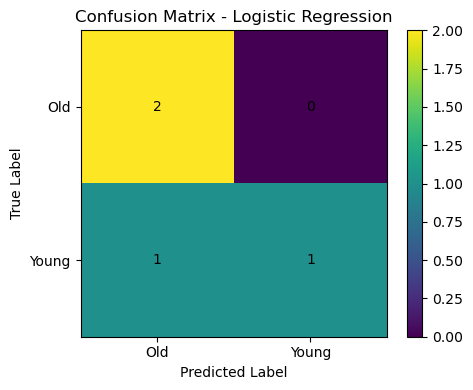

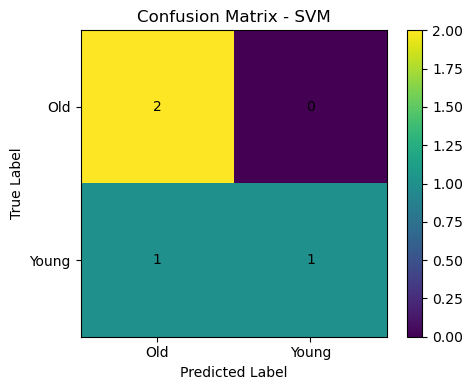

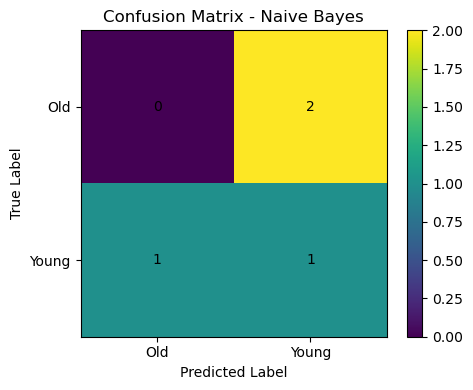

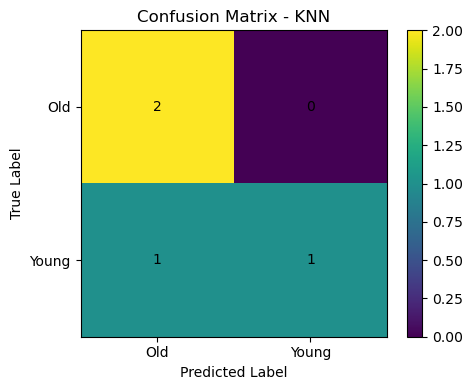

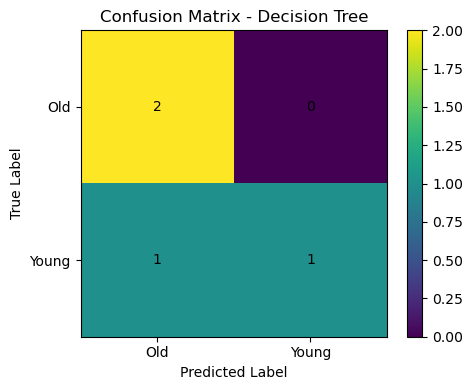

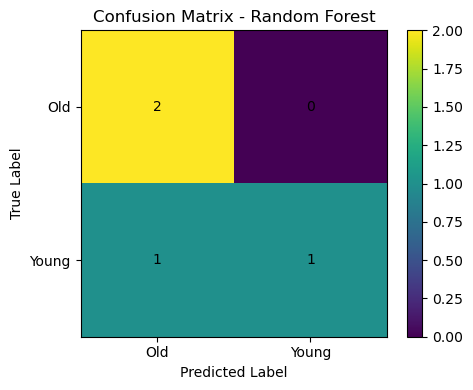

In [50]:

#Confusion matrix for each model
for name, model in trained_models.items():

    predictions = model.predict(
        X_test_scaled
    )

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(figsize=(5, 4))

    plt.imshow(cm)

    plt.title(
        "Confusion Matrix - " + name
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.xticks(
        range(len(label_encoder.classes_)),
        label_encoder.classes_
    )

    plt.yticks(
        range(len(label_encoder.classes_)),
        label_encoder.classes_
    )

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.colorbar()

    plt.tight_layout()
    plt.show()

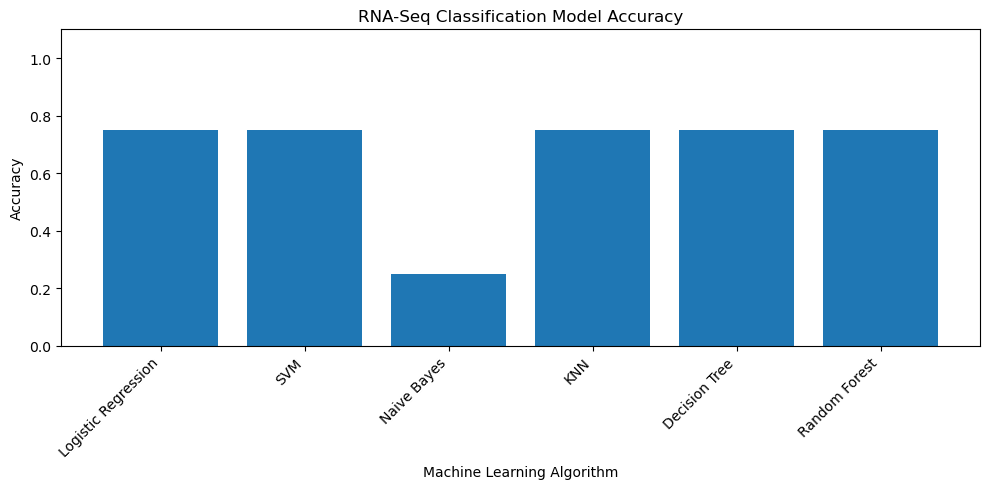

In [51]:
#Accuracy comparison plot
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy")

plt.title(
    "RNA-Seq Classification Model Accuracy"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(0, 1.1)

plt.tight_layout()

plt.show()

Explained variance ratio:
[0.60513185 0.07085176]

Total explained variance: 0.676


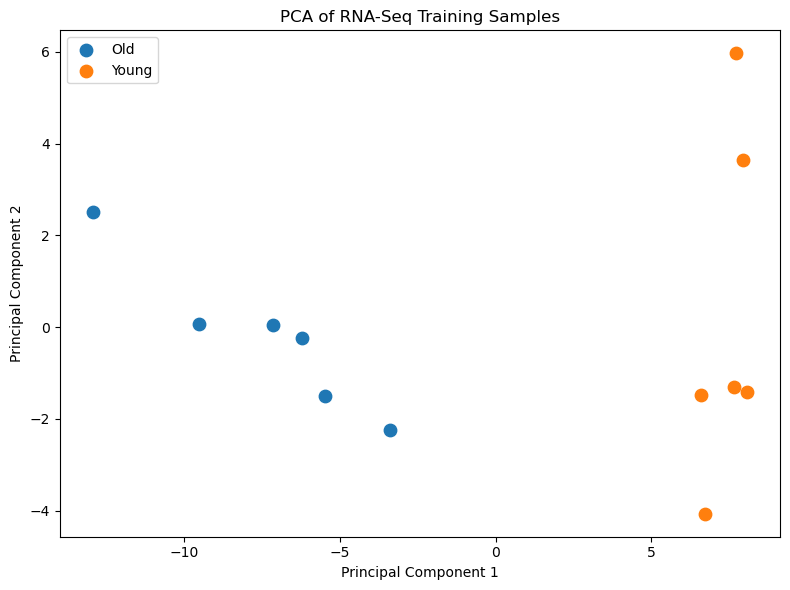

In [53]:
#PCA
pca = PCA(
    n_components=2,
    random_state=42
)

X_train_pca = pca.fit_transform(
    X_train_scaled
)

print(
    "Explained variance ratio:"
)

print(
    pca.explained_variance_ratio_
)

print(
    "\nTotal explained variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

#PCA Plot
plt.figure(figsize=(8, 6))

for class_value in np.unique(y_train):

    mask = y_train == class_value

    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        s=80,
        label=label_encoder.inverse_transform(
            [class_value]
        )[0]
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "PCA of RNA-Seq Training Samples"
)

plt.legend()

plt.tight_layout()

plt.show()

In [54]:
#Final summary
print("=" * 70)
print("RNA-SEQ MACHINE LEARNING SUMMARY")
print("=" * 70)

print(
    "Dataset: GSE263566"
)

print(
    "Total samples:",
    X.shape[0]
)

print(
    "Genes after filtering:",
    X.shape[1]
)

print(
    "Genes selected for ML:",
    X_train_selected.shape[1]
)

print(
    "Training samples:",
    X_train.shape[0]
)

print(
    "Testing samples:",
    X_test.shape[0]
)

print(
    "Number of models:",
    len(trained_models)
)

print("\nModel accuracy:")
display(results_df)

RNA-SEQ MACHINE LEARNING SUMMARY
Dataset: GSE263566
Total samples: 16
Genes after filtering: 24293
Genes selected for ML: 100
Training samples: 12
Testing samples: 4
Number of models: 6

Model accuracy:


,Model,Accuracy
0,Logistic Regression,0.75
1,SVM,0.75
2,Naive Bayes,0.25
3,KNN,0.75
4,Decision Tree,0.75
5,Random Forest,0.75


In [ ]:
# Conclusion

Machine learning classification was performed using the public
human RNA-Seq dataset GSE263566.

The dataset contained gene-expression profiles from 16 human
heart samples, consisting of Young and Old sample groups.

The expression matrix was inspected for missing values,
duplicate observations and invalid values. The dataset was
already processed and normalized, so additional CPM
normalization and log2 transformation were not performed.

The original gene-by-sample expression matrix was transposed
to create a sample-by-gene machine-learning feature matrix.

Zero-variance genes were removed before model development.
The data were divided into training and testing sets using a
stratified split.

Because the number of genes was much larger than the number of
samples, SelectKBest was used to select the most informative
genes. Feature selection was fitted only on the training data
to avoid information leakage.

The selected features were standardized using StandardScaler,
also fitted only on the training data.

Six classification algorithms were evaluated:

1. Logistic Regression
2. Support Vector Machine
3. Naive Bayes
4. K-Nearest Neighbors
5. Decision Tree
6. Random Forest

Model performance was evaluated using accuracy,
classification reports and confusion matrices. PCA was also
performed to visualize the distribution of the training
samples in a two-dimensional feature space.

The results demonstrate the application of a complete machine
learning workflow to real public RNA-Seq data.

However, the dataset contains only 16 samples. Therefore,
performance measurements from a single train-test split should
be interpreted as an educational demonstration of the machine
learning workflow rather than as evidence of generalizable
clinical or biological predictive performance.